In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
CM = '..//data//20_cmapss_fd001_sample.csv'

In [6]:
# ── [개념] CSV 열고 구조 확인 — read_csv · shape · head ──────────────────────
# 형식: df = pd.read_csv('파일.csv') → 연 직후 head/shape로 확인.
df = pd.read_csv(CM)
print(df.shape)     

(1116, 26)


In [4]:
print(df[['unit_nr', 'time_cycles', 's_2', 's_4']].head())

   unit_nr  time_cycles     s_2      s_4
0        1            1  641.17  1399.16
1        1            2  640.66  1399.28
2        1            3  641.08  1394.97
3        1            4  641.18  1404.10
4        1            5  641.13  1400.33


In [ ]:
# ── [개념] 변하는 센서 vs 안 변하는 센서 ────────────────────────────────────
# 형식: 표준편차가 0에 가까우면 정보 없음 → 제외 / 뚜렷이 변하면 활용.

In [5]:
print('s_1 표준편차:', round(df['s_1'].std(), 4))   # 0.0  (항상 상수 → 제외)
print('s_4 표준편차:', round(df['s_4'].std(), 4))   # 6.3932 (변함 → 활용)

s_1 표준편차: 0.0
s_4 표준편차: 6.3932


In [6]:
# ── [개념] 엔진 1대를 cycle 순으로 — 필터 → 정렬 → 그래프 ────────────────────

In [7]:
df.columns

Index(['unit_nr', 'time_cycles', 'setting_1', 'setting_2', 'setting_3', 's_1',
       's_2', 's_3', 's_4', 's_5', 's_6', 's_7', 's_8', 's_9', 's_10', 's_11',
       's_12', 's_13', 's_14', 's_15', 's_16', 's_17', 's_18', 's_19', 's_20',
       's_21'],
      dtype='str')

In [12]:
df.describe()

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
count,1116.000000,1116.000000,1116.000000,1116.000000,1116.0,1116.00,1116.000000,1116.000000,1116.000000,1.116000e+03,...,1116.000000,1116.000000,1116.000000,1116.000000,1.116000e+03,1116.000000,1116.0,1116.0,1116.000000,1116.000000
mean,3.050179,116.698925,-0.000068,0.000002,100.0,518.67,641.759973,1591.205681,1409.185699,1.462000e+01,...,517.447070,2388.100376,8137.583172,8.526198,3.000000e-02,394.005376,2388.0,100.0,38.448539,23.048273
std,1.441595,72.255767,0.001989,0.000301,0.0,0.00,0.497618,4.573376,6.393228,1.777153e-15,...,2.119054,0.075861,12.791277,0.077734,3.471002e-18,1.452373,0.0,0.0,0.272675,0.153079
min,1.000000,1.000000,-0.006500,-0.000900,100.0,518.67,640.290000,1575.480000,1389.130000,1.462000e+01,...,512.740000,2387.890000,8090.660000,8.333000,3.000000e-02,391.000000,2388.0,100.0,37.870000,22.703400
25%,2.000000,56.000000,-0.001400,-0.000200,100.0,518.67,641.380000,1587.970000,1404.560000,1.462000e+01,...,515.727500,2388.050000,8129.007500,8.464750,3.000000e-02,393.000000,2388.0,100.0,38.227500,22.922525
50%,3.000000,112.000000,-0.000100,0.000000,100.0,518.67,641.760000,1591.280000,1409.320000,1.462000e+01,...,517.490000,2388.100000,8137.785000,8.527000,3.000000e-02,394.000000,2388.0,100.0,38.450000,23.046750
75%,4.000000,168.000000,0.001300,0.000200,100.0,518.67,642.140000,1594.560000,1413.850000,1.462000e+01,...,519.220000,2388.150000,8145.992500,8.588000,3.000000e-02,395.000000,2388.0,100.0,38.670000,23.176600
max,5.000000,287.000000,0.006400,0.000900,100.0,518.67,643.060000,1604.850000,1426.610000,1.462000e+01,...,521.960000,2388.340000,8176.360000,8.722000,3.000000e-02,398.000000,2388.0,100.0,39.070000,23.445100


In [8]:
df[df['unit_nr'] == 1]

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,0.0010,-0.0000,100.0,518.67,641.17,1589.63,1399.16,14.62,...,520.73,2387.98,8132.98,8.344,0.03,391,2388,100.0,38.85,23.2468
1,1,2,0.0006,-0.0003,100.0,518.67,640.66,1589.52,1399.28,14.62,...,521.11,2387.97,8126.66,8.385,0.03,394,2388,100.0,38.89,23.2419
2,1,3,0.0016,-0.0004,100.0,518.67,641.08,1579.31,1394.97,14.62,...,520.15,2387.97,8124.71,8.436,0.03,392,2388,100.0,38.74,23.3084
3,1,4,-0.0008,-0.0002,100.0,518.67,641.18,1588.34,1404.10,14.62,...,520.76,2387.95,8115.96,8.430,0.03,393,2388,100.0,38.88,23.3398
4,1,5,0.0007,-0.0002,100.0,518.67,641.13,1589.93,1400.33,14.62,...,520.86,2387.91,8127.75,8.417,0.03,393,2388,100.0,38.84,23.2466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,1,188,0.0010,0.0003,100.0,518.67,642.60,1593.44,1416.30,14.62,...,515.06,2388.18,8153.24,8.713,0.03,395,2388,100.0,37.90,22.7164
188,1,189,0.0014,-0.0006,100.0,518.67,642.38,1598.12,1418.46,14.62,...,513.72,2388.24,8155.57,8.660,0.03,397,2388,100.0,37.92,22.8912
189,1,190,0.0030,0.0002,100.0,518.67,642.93,1591.91,1415.71,14.62,...,514.42,2388.21,8132.99,8.622,0.03,397,2388,100.0,38.07,22.8033
190,1,191,-0.0008,-0.0006,100.0,518.67,642.22,1602.67,1412.78,14.62,...,514.04,2388.34,8124.90,8.680,0.03,396,2388,100.0,38.07,22.8247


In [8]:
e1=df[df['unit_nr'] == 1].sort_values('time_cycles')

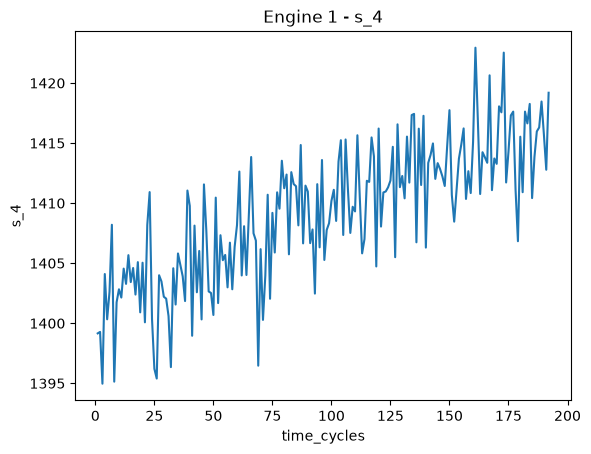

In [11]:
plt.plot(e1['time_cycles'], e1['s_4'])
plt.title('Engine 1 - s_4')
plt.xlabel('time_cycles')
plt.ylabel('s_4')
plt.show() # (우상향=열화)

In [1]:
# 실무 팁: 표준편차가 0에 가까운 센서(s_1, s_5, s_6, s_10, s_16, s_18, s_19 등)는 정보가 거의
# 없으므로 분석에서 제외합니다. 변하는 센서(s_2, s_3, s_4, s_7, s_11, s_12 등)에 집중하세요

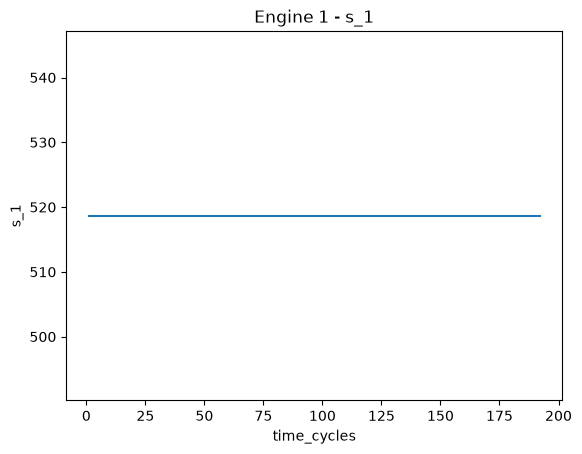

In [9]:
plt.plot(e1['time_cycles'], e1['s_1'])
plt.title('Engine 1 - s_1')
plt.xlabel('time_cycles')
plt.ylabel('s_1')
plt.show()

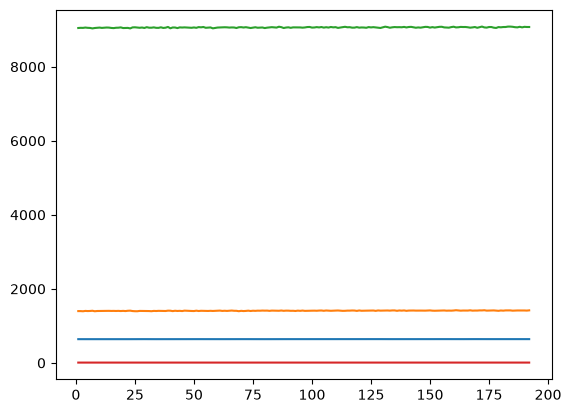

In [10]:
plt.plot(e1['time_cycles'], e1['s_2'])
plt.plot(e1['time_cycles'], e1['s_4'])
plt.plot(e1['time_cycles'], e1['s_9'])
plt.plot(e1['time_cycles'], e1['s_15'])
plt.show() # (우상향=열화)

In [12]:
df.isna().sum().sum()

np.int64(0)

In [13]:
# 실습 1 10시 30분까지

In [14]:
# ── [실습 1] C-MAPSS 데이터 열고 구조 확인 ──────────────────────────────────

In [15]:
df = pd.read_csv(CM)
print(df.shape)                                   # (1116, 26)
print(df.columns.tolist()[:5])                    # ['unit_nr','time_cycles','setting_1','setting_2','setting_3']
print(df[['unit_nr', 'time_cycles', 's_2', 's_11']].head())

(1116, 26)
['unit_nr', 'time_cycles', 'setting_1', 'setting_2', 'setting_3']
   unit_nr  time_cycles     s_2   s_11
0        1            1  641.17  47.28
1        1            2  640.66  47.06
2        1            3  641.08  47.18
3        1            4  641.18  47.16
4        1            5  641.13  47.19


In [16]:
# ── [실습 2] 엔진 단위와 작동 길이 파악 ─────────────────────────────────────

In [18]:
# 10시 35분까지 하시고 제출

In [19]:
df.columns

Index(['unit_nr', 'time_cycles', 'setting_1', 'setting_2', 'setting_3', 's_1',
       's_2', 's_3', 's_4', 's_5', 's_6', 's_7', 's_8', 's_9', 's_10', 's_11',
       's_12', 's_13', 's_14', 's_15', 's_16', 's_17', 's_18', 's_19', 's_20',
       's_21'],
      dtype='str')

In [20]:
df['unit_nr'].unique()

array([1, 2, 3, 4, 5])

In [21]:
df['unit_nr'].value_counts()

unit_nr
2    287
5    269
1    192
4    189
3    179
Name: count, dtype: int64

In [22]:
df['unit_nr'].value_counts().sort_index()

unit_nr
1    192
2    287
3    179
4    189
5    269
Name: count, dtype: int64

In [23]:
# 실습 3,4,5를 10시 50분까지 하시고 제출


In [25]:
# ── [실습 3] 요약 통계로 센서 범위 읽기 ─────────────────────────────────────
e2 = df[df['unit_nr'] == 2]

In [26]:
print(e2[['s_2', 's_11', 's_12']].describe().round(2))
# mean  641.75 / 47.69 / 517.43   (센서마다 크기·범위가 다름)

          s_2    s_11    s_12
count  287.00  287.00  287.00
mean   641.75   47.69  517.43
std      0.49    0.32    2.15
min    640.46   46.97  512.86
25%    641.39   47.42  515.66
50%    641.70   47.68  517.23
75%    642.14   47.94  519.16
max    642.87   48.44  521.96


In [27]:
# ── [실습 4] 변하는 센서 선별과 결측 확인

In [ ]:
['s_1', 's_6', 's_7', 's_11', 's_12']

In [28]:
for c in ['s_1', 's_6', 's_7', 's_11', 's_12']:
    print(c, round(df[c].std(), 3))               # s_1 0.0  s_6 0.0  s_7 2.367  s_11 0.314  s_12 2.119

s_1 0.0
s_6 0.0
s_7 2.367
s_11 0.314
s_12 2.119


In [29]:
print('결측 합계:', int(df.isna().sum().sum()))     # 0

결측 합계: 0


In [30]:
# ── [실습 5] 엔진 하나 골라 첫·끝 추세 읽기 ─────────────────────────────────

In [31]:
# ── [실습 5] 엔진 하나 골라 첫·끝 추세 읽기 ─────────────────────────────────
e2 = df[df['unit_nr'] == 2].sort_values('time_cycles')

In [32]:
# ['s_11', 's_7']

In [33]:
e2['s_11'].iloc[0]

np.float64(47.3)

In [34]:
e2['s_11'].iloc[-1]

np.float64(48.18)

In [35]:
e2['s_7'].iloc[0]

np.float64(553.84)

In [36]:
e2['s_7'].iloc[-1]

np.float64(546.17)

In [37]:
# ── [실습 5] 엔진 하나 골라 첫·끝 추세 읽기 ─────────────────────────────────
e2 = df[df['unit_nr'] == 2].sort_values('time_cycles')
for c in ['s_11', 's_7']:
    a, b = e2[c].iloc[0], e2[c].iloc[-1]
    print(c, a, '->', b, '상승' if b > a else '하강')
# s_11 47.3 -> 48.18 상승,   s_7 553.84 -> 546.17 하강

s_11 47.3 -> 48.18 상승
s_7 553.84 -> 546.17 하강


In [39]:
# 실습 6,7,8 11시 30분까지 후 제출


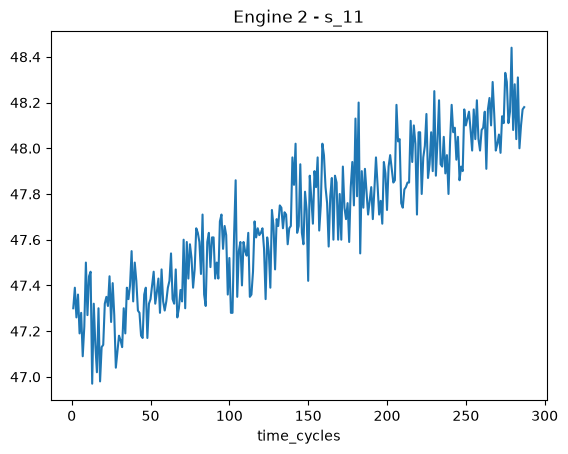

In [40]:
# ── [실습 6] 엔진 센서 시계열 그래프 그리기 ─────────────────────────────────
plt.plot(e2['time_cycles'], e2['s_11'])
plt.title('Engine 2 - s_11'); plt.xlabel('time_cycles')
plt.show()  #(우상향)

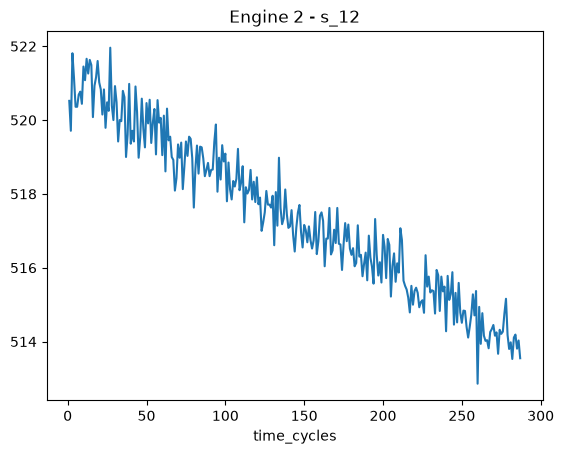

In [41]:
# ── [실습 6] 엔진 센서 시계열 그래프 그리기 ─────────────────────────────────
plt.plot(e2['time_cycles'], e2['s_12'])
plt.title('Engine 2 - s_12'); plt.xlabel('time_cycles')
plt.show()  #(우하향)

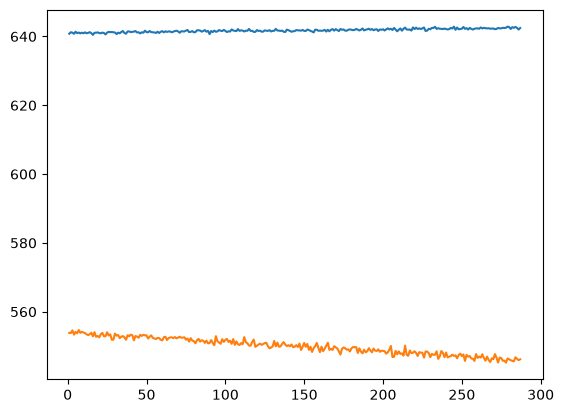

In [42]:
# ── [실습 7] 여러 센서 비교와 범위 문제 ─────────────────────────────────────
plt.plot(e2['time_cycles'], e2['s_2'], label='s_2')
plt.plot(e2['time_cycles'], e2['s_7'], label='s_7')
plt.show() # 비슷한 범위: 둘 다 보임

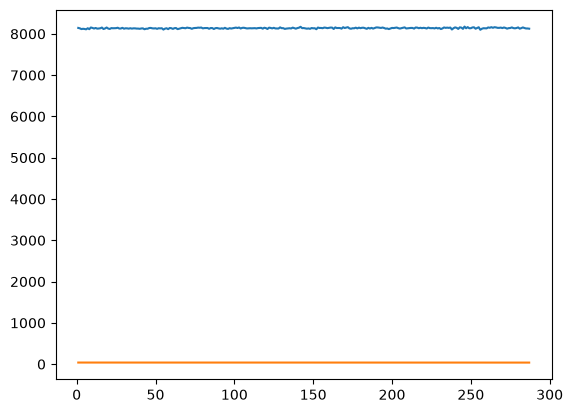

In [43]:
plt.plot(e2['time_cycles'], e2['s_14'], label='s_14')
plt.plot(e2['time_cycles'], e2['s_20'], label='s_20')
plt.show()  # 범위 차이 큼

In [44]:
print(round(e2['s_14'].min(), 1), round(e2['s_14'].max(), 1))   # 8099.1 8176.4
print(round(e2['s_20'].min(), 2), round(e2['s_20'].max(), 2))   # 37.88 39.06

8099.1 8176.4
37.88 39.06


In [45]:
# ── [실습 8] 데이터 구조 미니 리포트 — 캡스톤 ───────────────────────────────

In [46]:
target = 2

In [47]:
g = df[df['unit_nr'] == target].sort_values('time_cycles')

In [48]:
print(f'크기: {df.shape[0]}행 {df.shape[1]}열, 엔진 {df["unit_nr"].nunique()}대')
miss = '없음' if df.isna().sum().sum() == 0 else '있음'
print(f'엔진 {target} 회차 수: {len(g)}, 결측: {miss}')

크기: 1116행 26열, 엔진 5대
엔진 2 회차 수: 287, 결측: 없음


In [49]:
# ['s_11', 's_7', 's_12']
# s_11 : Static pressure at HPC outlet (고압 압축기 출구 정압력). Ps=static pressure
# s_7 :  Total pressure at HPC outlet (고압 압축기 출구 총압력)
#s_12 :  Ratio of fuel flow to Ps30 (연료 유량 / Ps30). phi=φ (그리스 문자)

In [50]:
for c in ['s_11', 's_7', 's_12']:
    a, b = g[c].iloc[0], g[c].iloc[-1]
    print(f'  {c}: {a} -> {b} ({"상승" if b > a else "하강"})')

  s_11: 47.3 -> 48.18 (상승)
  s_7: 553.84 -> 546.17 (하강)
  s_12: 520.52 -> 513.55 (하강)
